<a href="https://colab.research.google.com/github/knitinsuriya03-a11y/Exploratory-Data-Analysis-mini-project/blob/main/EDA_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the CSV. We use on_bad_lines='skip' to avoid crashing on extra unescaped commas.
df = pd.read_csv('Netflix_Data_Set.CSV', on_bad_lines='skip')

# If pandas incorrectly parsed the first column as the index (e.g. s1, s2, s5 etc.),
# we reset the index to move those values back into a column, and align the headers.
if df.index.name is None and list(df.index[:3]) != [0, 1, 2]:
    df = df.reset_index()
    # Rename columns to shift them correctly
    columns_to_use = ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']
    if len(df.columns) >= len(columns_to_use):
        # Slice to ensure correct column matching
        df = df.iloc[:, :len(columns_to_use)]
        df.columns = columns_to_use

# Ensure proper numeric datatypes
if 'release_year' in df.columns:
    df['release_year'] = pd.to_numeric(df['release_year'], errors='coerce')

# Check first 5 rows and basic info to confirm alignment
print("First 5 rows (Properly Aligned):")
display(df.head())

print("\nDataset Shape:", df.shape)
print("\nDataset Info:")
print(df.info())

First 5 rows (Properly Aligned):


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,The Vampire Diaries,Julie Plec,"Nina Dobrev, Paul Wesley, Ian Somerhalder, Jos...",United States,"September 15, 2017",2009,TV-14,8 Seasons,"TV Dramas, TV Mysteries, Supernatural Fantasy",Trapped in adolescent bodies
1,s2,TV Show,The Originals,Julie Plec,"Joseph Morgan, Daniel Gillies, Claire Holt, Ph...",United States,"October 1, 2018",2013,TV-14,5 Seasons,"TV Dramas, Supernatural Fantasy, TV Thrillers",The Original family of vampires settle down in...
2,s5,TV Show,Teen Wolf,Jeff Davis,"Tyler Posey, Crystal Reed, Dylan O'Brien, Tyle...",United States,"June 12, 2017",2011,TV-14,6 Seasons,"Teen TV Shows, Supernatural Fantasy, TV Action...",An average high school student and his best fr...
3,s6,TV Show,Chilling Adventures of Sabrina,NaN,"Kiernan Shipka, Ross Lynch, Lucy Davis, Mirand...",United States,"October 26, 2018",2018,TV-14,4 Seasons,"Supernatural Fantasy, Teen TV Shows, TV Horror",Magic and mischief collide as half-human
4,s10,TV Show,Shadow and Bone,Eric Heisserer,"Jessie Mei Li, Archie Renaux, Ben Barnes, Fred...",United States,"April 23, 2021",2021,TV-14,2 Seasons,"Sci-Fi & Fantasy, TV Action & Adventure, TV Dr...",Dark forces conspire against orphan mapmaker A...



Dataset Shape: (35, 12)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       35 non-null     object
 1   type          35 non-null     object
 2   title         35 non-null     object
 3   director      31 non-null     object
 4   cast          33 non-null     object
 5   country       34 non-null     object
 6   date_added    34 non-null     object
 7   release_year  35 non-null     int64 
 8   rating        35 non-null     object
 9   duration      35 non-null     object
 10  listed_in     35 non-null     object
 11  description   35 non-null     object
dtypes: int64(1), object(11)
memory usage: 3.4+ KB
None


In [ ]:
# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Fill missing values
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')

# Convert date_added to datetime and get the year
# Convert to string first to allow string operations in case it is loaded as numeric
df['date_added'] = pd.to_datetime(df['date_added'].astype(str).str.strip(), errors='coerce')
df['date_added'] = df['date_added'].fillna(df['date_added'].mode()[0])
df['year_added'] = df['date_added'].dt.year

# Extract numeric numbers from duration column (using raw string r'\d+' to fix the SyntaxWarning)
# We use the nullable integer type 'Int64' to allow keeping NaN values without raising an error
df['duration_num'] = df['duration'].str.extract(r'(\d+)').astype('Int64')

# Check if all missing values are gone
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
show_id          0
type             0
title            4
director         0
cast             0
country          0
date_added       0
release_year     0
rating           0
duration         0
listed_in        0
description     17
year_added       0
duration_num    34
dtype: int64


### 1. Movies vs TV Shows (Pie Chart)

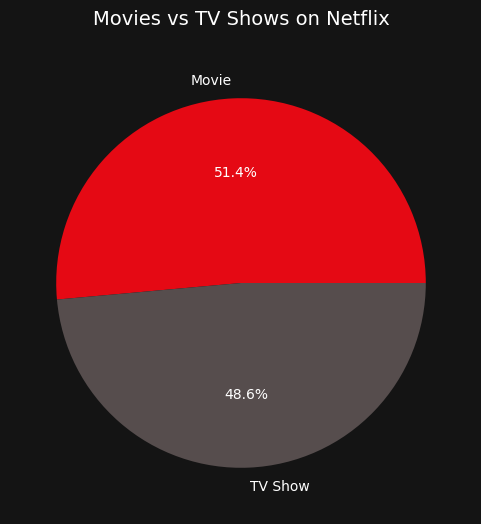

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set the plotting style to match the Netflix dark theme
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#141414'
plt.rcParams['axes.facecolor'] = '#141414'

# Ensure required column calculations are in place
if 'year_added' not in df.columns:
    df['date_added'] = pd.to_datetime(df['date_added'].astype(str).str.strip(), errors='coerce')
    mode_val = df['date_added'].mode()
    df['date_added'] = df['date_added'].fillna(mode_val[0] if not mode_val.empty else pd.Timestamp('2021-01-01'))
    df['year_added'] = df['date_added'].dt.year

if 'duration_num' not in df.columns:
    df['duration_num'] = df['duration'].str.extract(r'(\d+)').astype('Int64')

# Plotting Pie Chart
fig, ax = plt.subplots(figsize=(6, 6))
fig.patch.set_facecolor('#141414')
ax.set_facecolor('#141414')

type_counts = df['type'].value_counts()
if not type_counts.empty:
    plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', colors=['#E50914', '#564d4d'], textprops={'color': 'white'})
    plt.title('Movies vs TV Shows on Netflix', color='white', fontsize=14, pad=20)
    plt.show()
else:
    print("No standard 'Movie' or 'TV Show' types found in the 'type' column.")

### 2. Content Added Over the Years (Line Chart)

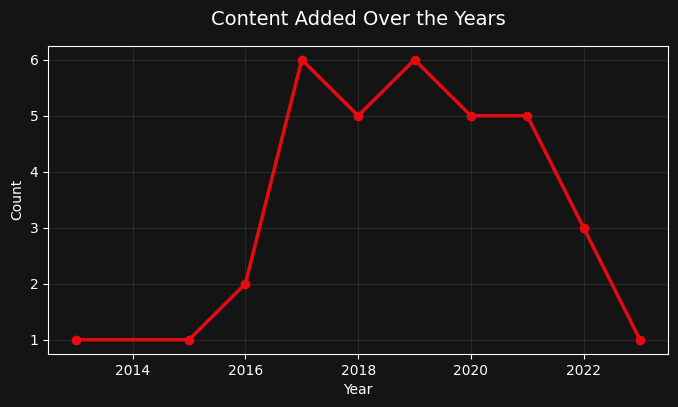

In [ ]:
# Set dark background styles
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#141414'
plt.rcParams['axes.facecolor'] = '#141414'

fig, ax = plt.subplots(figsize=(8, 4))
fig.patch.set_facecolor('#141414')
ax.set_facecolor('#141414')

yearly_data = df['year_added'].value_counts().sort_index()
plt.plot(yearly_data.index, yearly_data.values, marker='o', color='#E50914', linewidth=2.5)
plt.title('Content Added Over the Years', color='white', fontsize=14, pad=15)
plt.xlabel('Year', color='white')
plt.ylabel('Count', color='white')
plt.grid(True, alpha=0.2, color='gray')
plt.show()

### 3. Top Producing Countries (Bar Chart)

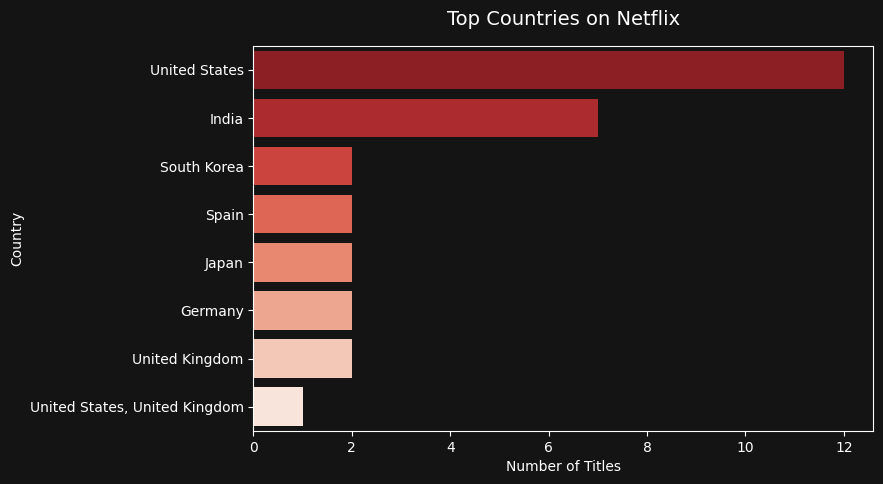

In [ ]:
# Set dark background styles
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#141414'
plt.rcParams['axes.facecolor'] = '#141414'

fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor('#141414')
ax.set_facecolor('#141414')

top_countries = df[df['country'] != 'Unknown']['country'].value_counts().head(8)
if not top_countries.empty:
    # Use a custom red gradient palette
    reds_palette = sns.color_palette("Reds_r", n_colors=len(top_countries))
    sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index, palette=reds_palette, legend=False)
    plt.title('Top Countries on Netflix', color='white', fontsize=14, pad=15)
    plt.xlabel('Number of Titles', color='white')
    plt.ylabel('Country', color='white')
    plt.show()
else:
    print("No country data available to plot.")

### 4. Movie Duration Distribution (Histogram)

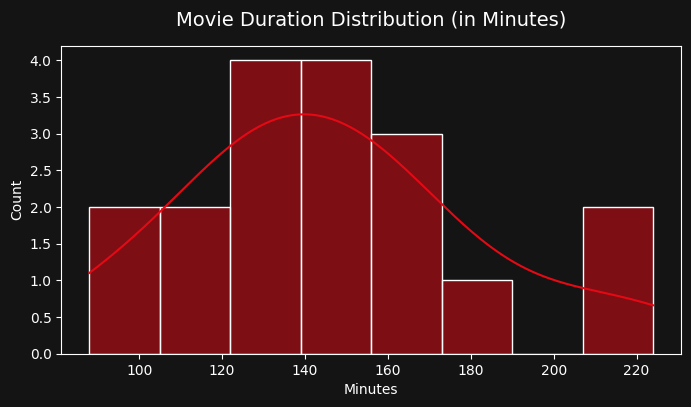

In [ ]:
# Set dark background styles
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#141414'
plt.rcParams['axes.facecolor'] = '#141414'

fig, ax = plt.subplots(figsize=(8, 4))
fig.patch.set_facecolor('#141414')
ax.set_facecolor('#141414')

movies = df[df['type'] == 'Movie']
if not movies.empty and not movies['duration_num'].dropna().empty:
    sns.histplot(movies['duration_num'].dropna().astype(float), bins=8, kde=True, color='#E50914')
    plt.title('Movie Duration Distribution (in Minutes)', color='white', fontsize=14, pad=15)
    plt.xlabel('Minutes', color='white')
    plt.ylabel('Count', color='white')
    plt.show()
else:
    print("No Movie durations available to plot (The dataset currently has only TV Shows).")

### 1. Correlation Heatmap of Netflix Numeric Features

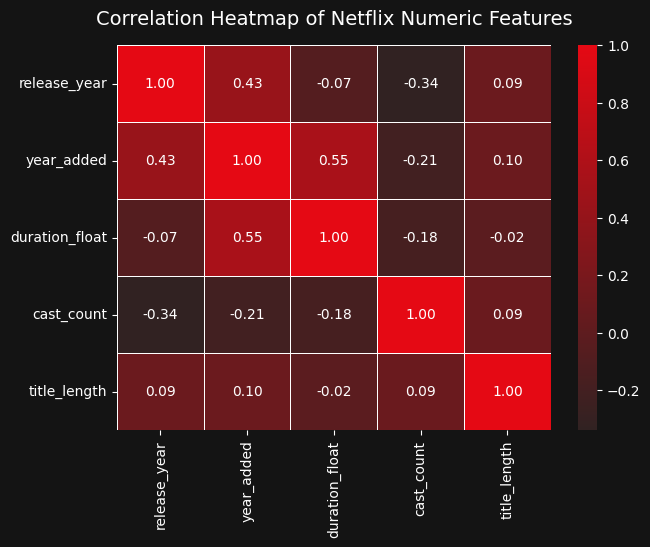

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set dark background styles
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#141414'
plt.rcParams['axes.facecolor'] = '#141414'

# Ensure extra features exist
df['cast_count'] = df['cast'].apply(lambda x: 0 if x == 'Unknown' else len(str(x).split(',')))
df['title_length'] = df['title'].str.len()

# Convert duration_num to float so correlation matrix and heatmaps process it correctly
df['duration_float'] = df['duration_num'].astype(float)

fig, ax = plt.subplots(figsize=(7, 5))
fig.patch.set_facecolor('#141414')
ax.set_facecolor('#141414')

num_cols = ['release_year', 'year_added', 'duration_float', 'cast_count', 'title_length']
corr_matrix = df[num_cols].corr()

# Use a red custom cmap for the correlation matrix
sns.heatmap(corr_matrix, annot=True, cmap=sns.dark_palette("#E50914", as_cmap=True), fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Netflix Numeric Features', color='white', fontsize=14, pad=15)
plt.show()

### 2. Pair Plot (Comparing Movies vs TV Shows)

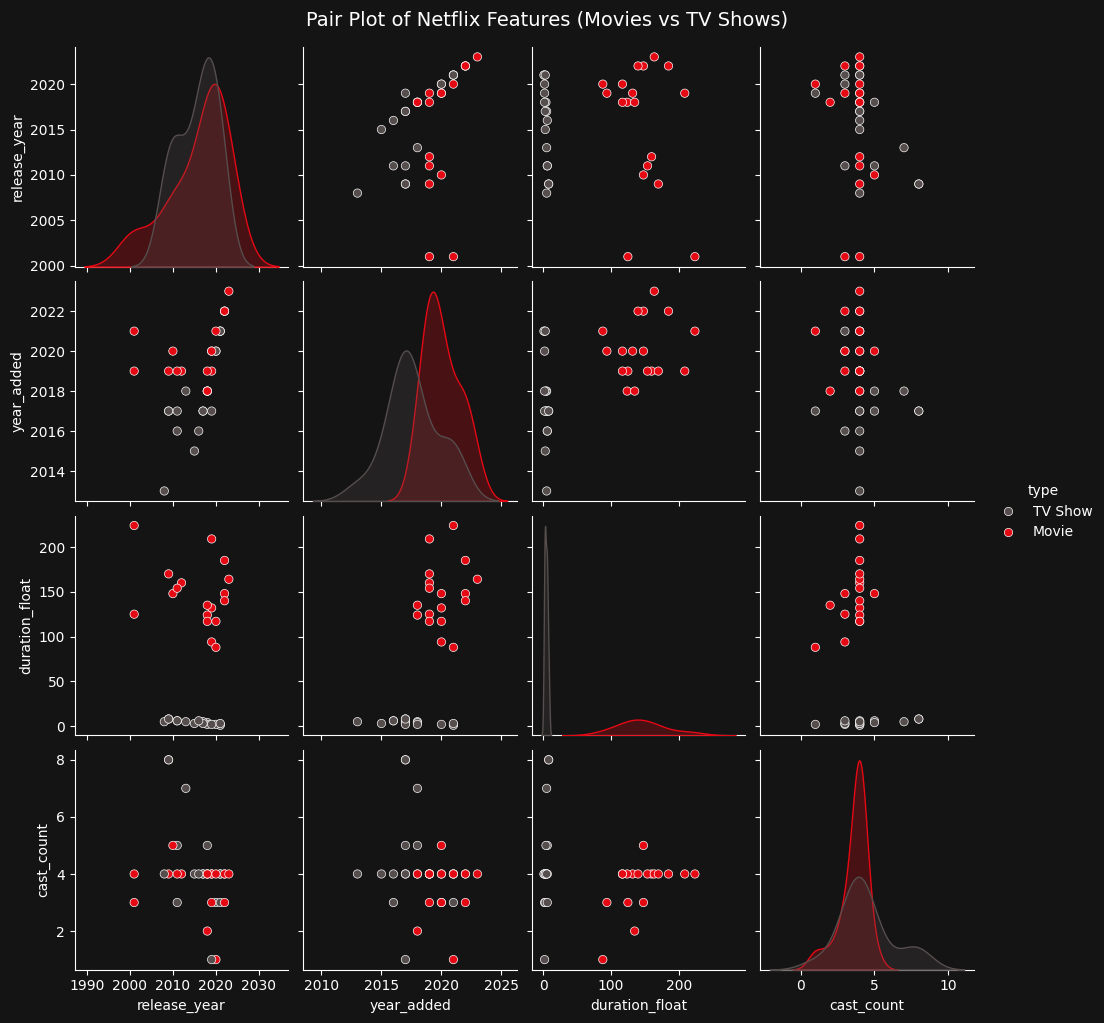

In [ ]:
# Set dark background styles
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#141414'
plt.rcParams['axes.facecolor'] = '#141414'

# Apply the styling to the pair plot
with plt.rc_context({'figure.facecolor': '#141414', 'axes.facecolor': '#141414'}):
    pair_plot = sns.pairplot(
        df[['type', 'release_year', 'year_added', 'duration_float', 'cast_count']],
        hue='type',
        palette={'Movie': '#E50914', 'TV Show': '#564d4d'},
        diag_kind='kde'
    )
    pair_plot.fig.suptitle('Pair Plot of Netflix Features (Movies vs TV Shows)', y=1.02, color='white', fontsize=14)
    for ax in pair_plot.axes.flatten():
        if ax is not None:
            ax.tick_params(colors='white')
            ax.yaxis.label.set_color('white')
            ax.xaxis.label.set_color('white')
    plt.show()

### 3. Linear Regression Plot (Movie Release Year vs Movie Duration)

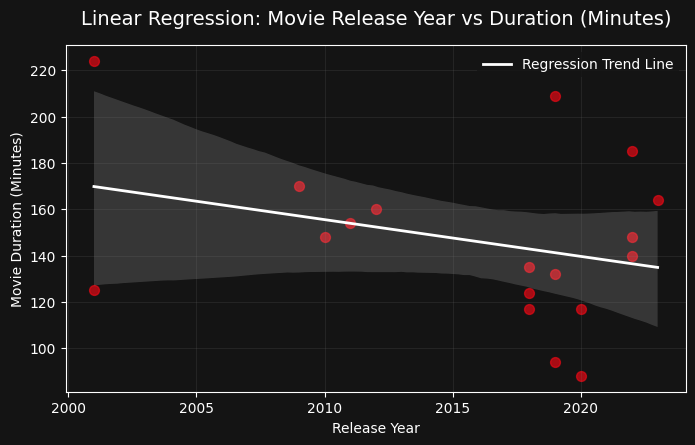

In [ ]:
# Set dark background styles
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#141414'
plt.rcParams['axes.facecolor'] = '#141414'

fig, ax = plt.subplots(figsize=(8, 4.5))
fig.patch.set_facecolor('#141414')
ax.set_facecolor('#141414')

movies = df[df['type'] == 'Movie'].dropna(subset=['duration_float'])

# Safely run regplot with float data
sns.regplot(
    x='release_year',
    y='duration_float',
    data=movies,
    color='#E50914',
    scatter_kws={'s': 50, 'alpha': 0.7},
    line_kws={'color': 'white', 'label': 'Regression Trend Line', 'linewidth': 2}
)
plt.title('Linear Regression: Movie Release Year vs Duration (Minutes)', color='white', fontsize=14, pad=15)
plt.xlabel('Release Year', color='white')
plt.ylabel('Movie Duration (Minutes)', color='white')
plt.legend(facecolor='#141414', edgecolor='none')
plt.grid(True, alpha=0.15, color='gray')
plt.show()

### TVDU Analysis: 1. Compare IMDb Ratings and Seasons of the 3 Shows

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the TVD Universe dataset
tvd_df = pd.read_csv('TVD_Data_Set.CSV')

print("TVDU Dataset Preview:")
display(tvd_df.head())

# Compare IMDb Ratings and Seasons of the 3 shows
show_stats = tvd_df.groupby('primary_series')[['show_seasons', 'show_total_episodes', 'show_imdb_rating']].first()
print("\nShow Comparison:")
display(show_stats)

TVDU Dataset Preview:


,record_id,character_name,actor_name,primary_series,species,tvd_episodes,to_episodes,legacies_episodes,total_universe_episodes,show_seasons,show_total_episodes,show_imdb_rating,release_year,end_year,maturity_rating,primary_setting,character_archetype
0,1,Klaus Mikaelson,Joseph Morgan,The Originals,Original Hybrid (Vampire/Werewolf),48,92,1,141,5,92,8.3,2013,2018,TV-14,"New Orleans, Louisiana",Ruthless Strategist & Loyal Protector
1,2,Stefan Salvatore,Paul Wesley,The Vampire Diaries,Vampire,171,1,0,172,8,171,7.7,2009,2017,TV-14,"Mystic Falls, Virginia",Selfless & Empathetic Hero
2,3,Damon Salvatore,Ian Somerhalder,The Vampire Diaries,Vampire,171,0,0,171,8,171,7.7,2009,2017,TV-14,"Mystic Falls, Virginia",Impulsive & Defiant Anti-Hero
3,4,Elijah Mikaelson,Daniel Gillies,The Originals,Original Vampire,23,85,0,108,5,92,8.3,2013,2018,TV-14,"New Orleans, Louisiana",Noble & Honor-Bound Enforcer
4,5,Rebekah Mikaelson,Claire Holt,The Originals,Original Vampire,37,37,2,76,5,92,8.3,2013,2018,TV-14,"New Orleans, Louisiana",Fierce & Devoted Sister



Show Comparison:


,show_seasons,show_total_episodes,show_imdb_rating
primary_series,,,
Legacies,4,68,7.3
The Originals,5,92,8.3
The Vampire Diaries,8,171,7.7


### TVDU Analysis: 2. Bar Chart of IMDb Ratings

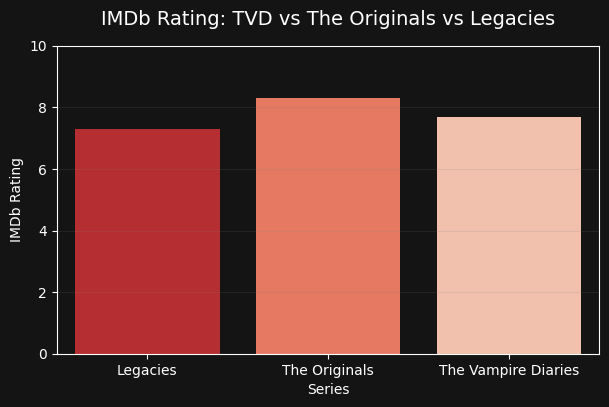

In [ ]:
# Set dark background styles
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#141414'
plt.rcParams['axes.facecolor'] = '#141414'

fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#141414')
ax.set_facecolor('#141414')

sns.barplot(
    x=show_stats.index,
    y=show_stats['show_imdb_rating'],
    hue=show_stats.index,
    palette=sns.color_palette("Reds_r", n_colors=len(show_stats)),
    legend=False
)
plt.title('IMDb Rating: TVD vs The Originals vs Legacies', color='white', fontsize=14, pad=15)
plt.ylim(0, 10)
plt.ylabel('IMDb Rating', color='white')
plt.xlabel('Series', color='white')
plt.grid(True, axis='y', alpha=0.15, color='gray')
plt.show()

### TVDU Analysis: 3. Top 10 Characters with Most Episodes in the Universe

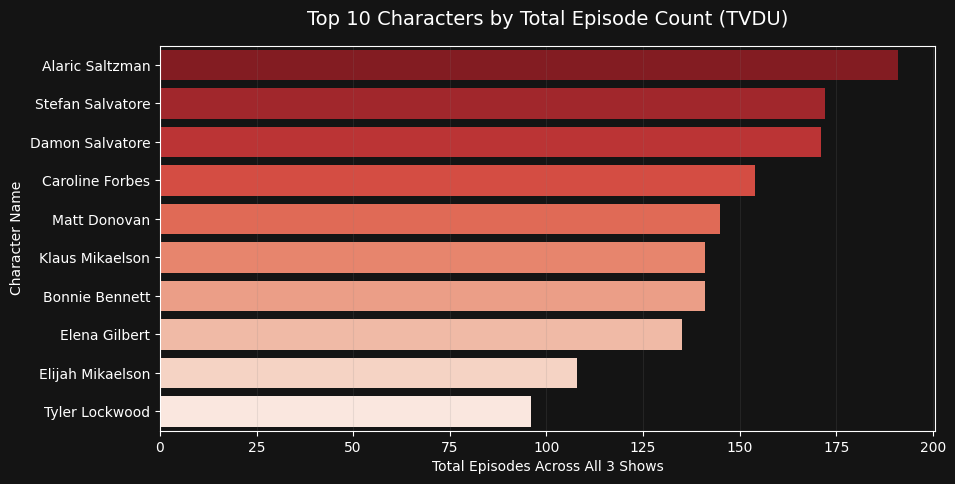

In [ ]:
# Set dark background styles
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#141414'
plt.rcParams['axes.facecolor'] = '#141414'

top_10_chars = tvd_df.sort_values(by='total_universe_episodes', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor('#141414')
ax.set_facecolor('#141414')

sns.barplot(
    x='total_universe_episodes',
    y='character_name',
    data=top_10_chars,
    hue='character_name',
    palette=sns.color_palette("Reds_r", n_colors=10),
    legend=False
)
plt.title('Top 10 Characters by Total Episode Count (TVDU)', color='white', fontsize=14, pad=15)
plt.xlabel('Total Episodes Across All 3 Shows', color='white')
plt.ylabel('Character Name', color='white')
plt.grid(True, axis='x', alpha=0.15, color='gray')
plt.show()